# Morphological Operations: Dilation, Erosion, Opening & Closing

Comparing four structuring elements: Square (7x7), Cross (7x7), Vertical Line (1x9), and Horizontal Line (9x1) on a descriptive image (`coins.png`).


### 1. Structuring Elements
- **Square (7x7)**: All 8 directions (`cv2.MORPH_RECT`)
- **Cross (7x7)**: 4 cardinal directions (`cv2.MORPH_CROSS`)
- **Vertical Line (1x9)**: Vertical only (`1x9`)
- **Horizontal Line (9x1)**: Horizontal only (`9x1`)


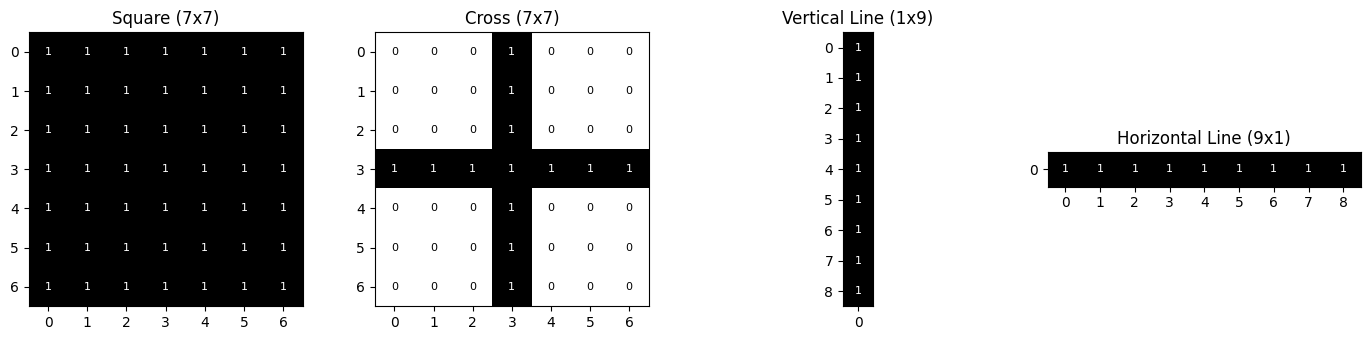

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

se_sq   = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7))
se_cr   = cv2.getStructuringElement(cv2.MORPH_CROSS, (7, 7))
se_vert = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 9))
se_horz = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 1))

kernels = [
    ('Square (7x7)', se_sq),
    ('Cross (7x7)', se_cr),
    ('Vertical Line (1x9)', se_vert),
    ('Horizontal Line (9x1)', se_horz)
]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (title, k) in zip(axes, kernels):
    ax.imshow(k, cmap='gray_r', vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xticks(range(k.shape[1]))
    ax.set_yticks(range(k.shape[0]))
    for i in range(k.shape[0]):
        for j in range(k.shape[1]):
            ax.text(j, i, str(k[i, j]), ha='center', va='center',
                    color='white' if k[i, j] == 1 else 'black', fontsize=8)
plt.tight_layout()
plt.show()


### 2. Load Descriptive Image
We load `coins.png` and binarize using Otsu thresholding.


In [2]:
img_path = 'coins.png' if os.path.exists('coins.png') else 'week5/coins.png'
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
_, test_img = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Loaded coins: {test_img.shape[1]}x{test_img.shape[0]} px")


Loaded coins: 384x303 px


### 3. Dilation (cv2.dilate)


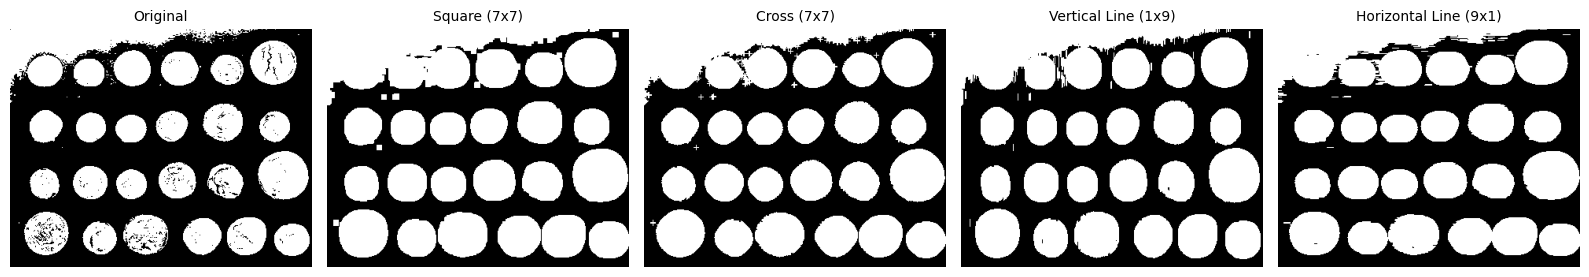

In [3]:
d_square   = cv2.dilate(test_img, se_sq)
d_cross    = cv2.dilate(test_img, se_cr)
d_vertical = cv2.dilate(test_img, se_vert)
d_horiz    = cv2.dilate(test_img, se_horz)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
titles = ['Original', 'Square (7x7)', 'Cross (7x7)', 'Vertical Line (1x9)', 'Horizontal Line (9x1)']
imgs = [test_img, d_square, d_cross, d_vertical, d_horiz]

for ax, t, im in zip(axes, titles, imgs):
    ax.imshow(im, cmap='gray')
    ax.set_title(t, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()


**Observed Changes:**
Dilation expands the foreground boundaries and fills small interior cavities. As a result, the coins appear thicker, surface details and engravings fill in, and closely adjacent coins merge together into continuous clusters.


### 4. Erosion (cv2.erode)


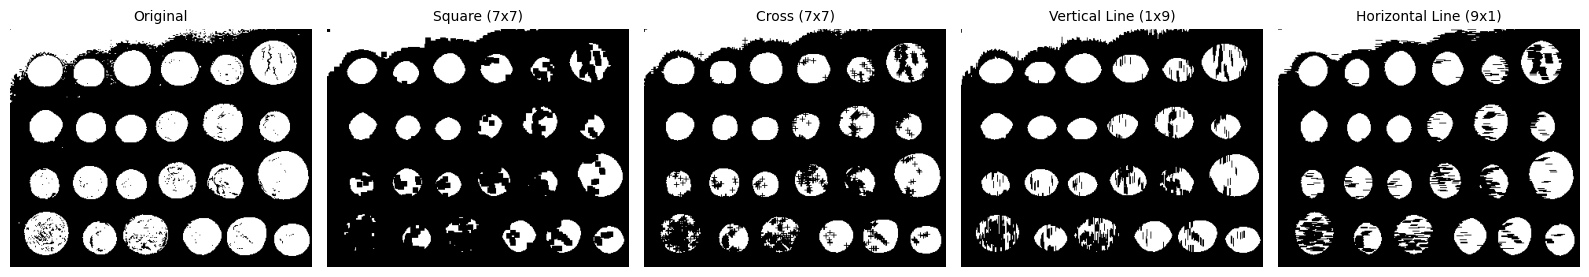

In [4]:
e_square   = cv2.erode(test_img, se_sq)
e_cross    = cv2.erode(test_img, se_cr)
e_vertical = cv2.erode(test_img, se_vert)
e_horiz    = cv2.erode(test_img, se_horz)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
imgs = [test_img, e_square, e_cross, e_vertical, e_horiz]

for ax, t, im in zip(axes, titles, imgs):
    ax.imshow(im, cmap='gray')
    ax.set_title(t, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()


**Observed Changes:**
Erosion shrinks the foreground boundaries and eliminates thin, delicate features. As a result, the coins appear smaller, fine surface details disappear, and coins that were slightly touching become separated.


### 5. Opening (cv2.morphologyEx - MORPH_OPEN)


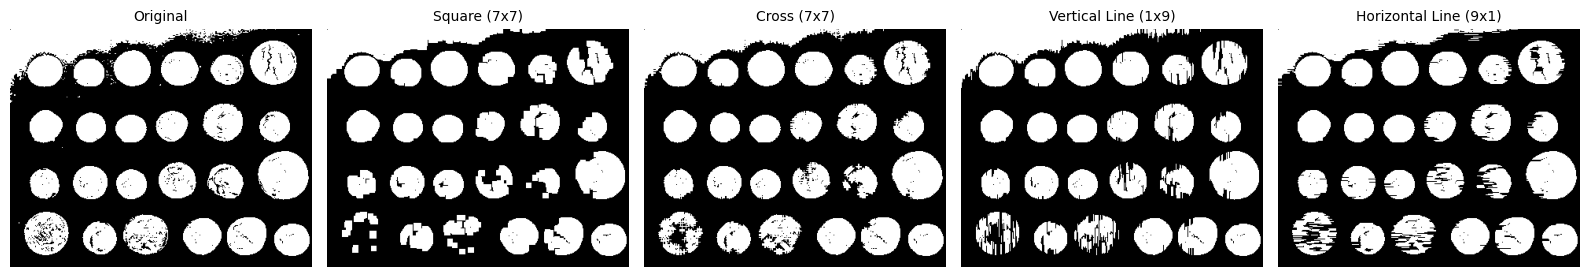

In [5]:
o_square   = cv2.morphologyEx(test_img, cv2.MORPH_OPEN, se_sq)
o_cross    = cv2.morphologyEx(test_img, cv2.MORPH_OPEN, se_cr)
o_vertical = cv2.morphologyEx(test_img, cv2.MORPH_OPEN, se_vert)
o_horiz    = cv2.morphologyEx(test_img, cv2.MORPH_OPEN, se_horz)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
imgs = [test_img, o_square, o_cross, o_vertical, o_horiz]

for ax, t, im in zip(axes, titles, imgs):
    ax.imshow(im, cmap='gray')
    ax.set_title(t, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()


**Observed Changes:**
Opening (erosion followed by dilation) removes small isolated foreground noise, thin protrusions, and weak connecting bridges without significantly altering the overall size or shape of the coins.


### 6. Closing (cv2.morphologyEx - MORPH_CLOSE)


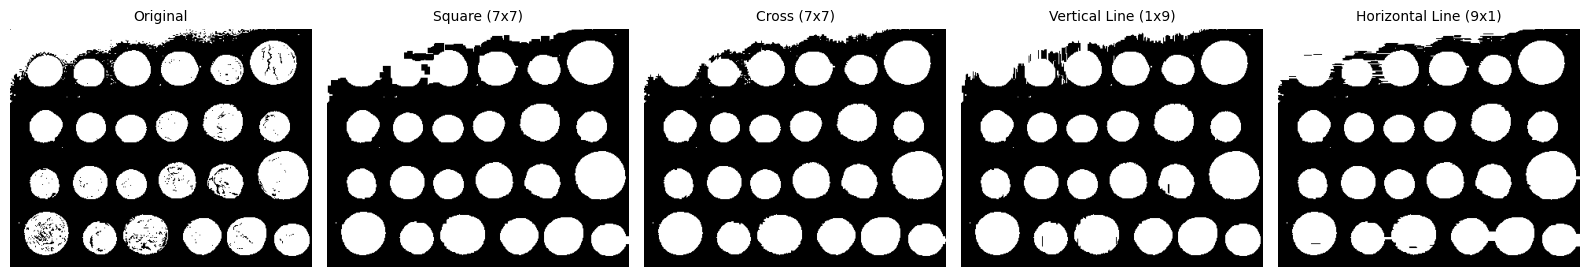

In [6]:
c_square   = cv2.morphologyEx(test_img, cv2.MORPH_CLOSE, se_sq)
c_cross    = cv2.morphologyEx(test_img, cv2.MORPH_CLOSE, se_cr)
c_vertical = cv2.morphologyEx(test_img, cv2.MORPH_CLOSE, se_vert)
c_horiz    = cv2.morphologyEx(test_img, cv2.MORPH_CLOSE, se_horz)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
imgs = [test_img, c_square, c_cross, c_vertical, c_horiz]

for ax, t, im in zip(axes, titles, imgs):
    ax.imshow(im, cmap='gray')
    ax.set_title(t, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()


**Observed Changes:**
Closing (dilation followed by erosion) fills small holes, dark gaps, and surface engravings inside the coins, producing smoother and more solid contours without noticeably expanding the overall coin boundaries.
